<div align="center" style="padding:40px 24px;background:linear-gradient(135deg,#0e1a2e 0%,#13223b 100%);border-radius:14px;border-bottom:5px solid #ffd43b;">
  <p style="margin:0;color:#6aaef0;font-family:monospace;font-weight:700;font-size:14px;letter-spacing:.16em;text-transform:uppercase;">The AI Learning Hub · Lesson 03 · Applied AI: unstructured data</p>
  <h1 style="margin:14px 0 6px;color:#f1f5fb;font-size:42px;">02.4 · Tweets: Transformers</h1>
  <p style="margin:0;color:#b4c2d8;font-size:18px;">Can a pre-trained language model read sentiment better than word counts?</p>
</div>

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/the-ai-learning-hub/03-applied-ai-projects/blob/main/01_text_mining/02_project_tweets/02.4_Tweets_Transformers.ipynb) [![Slides](https://img.shields.io/badge/slides-Lesson_03-ffd43b)](https://the-ai-learning-hub.github.io/03-applied-ai-projects/#tweets)

## 🎯 Objectives
By the end of this notebook you will be able to:

- classify tweets with a ready-made Hugging Face **`pipeline`**, with **no training at all**, and see why the *label mapping* matters;
- compare three **pre-trained sentiment models** (movie reviews, IMDb, tweets) on the 9,926 test tweets;
- **fine-tune** a pre-trained transformer on our 35,730 training tweets with the Hugging Face `Trainer` and **early stopping**;
- read the **training curves** and compare six fine-tuned models in one table;
- see how **Optuna** can search for good hyperparameters.

**⏱️ Duration:** ≈ 30 min of reading · **📋 Prerequisites:** notebooks 02.0–02.3 (EDA, baselines, lexicons, classic machine learning) · **▶️ How to use:** read the notebook top to bottom; the saved outputs are from the original run.

> ⏳ **Heavy notebook.** Almost every model cell here needs a GPU. All the outputs were saved from the original run on an **NVIDIA GeForce RTX 4060 (8 GB)**, so you can read and learn without running anything. On a CPU the fine-tuning would take many hours.

*Based on the Text Mining project by Diogo Freitas, João Francisco Botas and Ana Sofia Trabulo (ISCTE, 2024/25).*

## 📑 Contents

- [⚙️ Setup](#setup)
0. [📥 Reading the data](#sec-0)
1. [🧪 Simple experiments with pipelines (no fine-tuning)](#sec-1)
2. [🏋️ Fine-tuning pre-trained models](#sec-2)
3. [📊 Results](#sec-3)
4. [🔧 Optuna (hyperparameter search)](#sec-4)
5. [🏆 Comparing the results](#sec-5)
6. [🏁 The whole project](#sec-6)
- [📌 Summary](#summary)

> 🔗 **Google Colab with more powerful models.** The authors also prepared a Colab notebook with a selection of **newer, more powerful NLP models**, suited to tasks such as **text classification** and **explicit-language detection**, among others:
>
> 👉 [Open the Colab with powerful models](https://colab.research.google.com/drive/13CIBPqO8YfA_TLknJBl1QAcMoWstwHAo?usp=sharing)
>
> It is optimised to run on a GPU (such as the free **Tesla T4**) and includes models like **DeBERTa v3**, **E5**, **GTE** and **BGE**.

<a id="setup"></a>

## ⚙️ Setup

Imports and paths.

In [1]:
# ⚙️ Setup: works locally (VS Code / Jupyter) and in Google Colab
import os
import subprocess
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    ROOT = Path("/content/03-applied-ai-projects")
    if not ROOT.exists():
        subprocess.run(["git", "clone", "--depth", "1",
                        "https://github.com/the-ai-learning-hub/03-applied-ai-projects.git", str(ROOT)], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "datasets", "tensorboard"], check=True)
else:  # locally: walk up until we find the folder that has src/ and data/
    ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir() and (p / "data").is_dir())
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from datasets import Dataset
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix, f1_score,
                             precision_score, recall_score)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from tqdm import tqdm
from transformers import AutoModelForSequenceClassification, AutoTokenizer, Trainer, TrainingArguments

from src.paths import data_dir, models_dir

pd.set_option('display.max_colwidth', None)  # show the full text
TWEETS = data_dir("tweets") / "tweets"  # tweets_train.csv and tweets_test.csv (downloaded on first use)
HERE = ROOT / "01_text_mining" / "02_project_tweets"  # this project's folder (images/, results/)

print("Project root:", ROOT.name, "(Colab)" if IN_COLAB else "(local)")

Project root: 03-applied-ai-projects (local)


> 💡 **Tip:** locally, run `uv sync` once and pick the `.venv` kernel. This notebook also needs `datasets` (and `tensorboard` for the training logs): `uv pip install datasets tensorboard`. The pre-trained models (≈ 250–500 MB each) download on first use into the Hugging Face cache.

### Helper functions

The confusion matrix and the performance report are shared by the whole tweet project (`src/tweet_tools.py`). The function below draws the training curves saved by the Hugging Face `Trainer`.

In [2]:
from src.tweet_tools import clean_text, plot_confusion_matrix, print_classification_report


def plot_training_history_from_trainer(trainer, model_name="Model"):
    import matplotlib.pyplot as plt

    logs = trainer.state.log_history

    train_loss = []
    val_loss = []
    val_acc = []
    f1_scores = []
    epochs_eval = []
    epochs_train = []

    for entry in logs:
        if 'loss' in entry and 'epoch' in entry and 'eval_loss' not in entry:
            train_loss.append(entry['loss'])
            epochs_train.append(entry['epoch'])
        if 'eval_loss' in entry:
            val_loss.append(entry['eval_loss'])
            val_acc.append(entry.get('eval_accuracy'))
            f1_scores.append(entry.get('eval_f1'))
            epochs_eval.append(entry['epoch'])

    plt.figure(figsize=(14, 5))

    # Loss
    plt.subplot(1, 2, 1)
    plt.plot(epochs_train, train_loss, label="Train Loss", marker='o')
    plt.plot(epochs_eval, val_loss, label="Val Loss", marker='o')
    plt.title(f"Loss - {model_name}")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()
    plt.grid(True)

    # Accuracy + F1-score
    plt.subplot(1, 2, 2)
    plt.plot(epochs_eval, val_acc, label="Val Accuracy", color='green', marker='o')
    plt.plot(epochs_eval, f1_scores, label="F1-score", color='purple', marker='o')
    plt.title(f"Accuracy & F1 - {model_name}")
    plt.xlabel("Epoch")
    plt.ylabel("Score")
    plt.ylim(0.8, 1.0)
    plt.legend()
    plt.grid(True)

    plt.tight_layout()
    plt.show()

<a id="sec-0"></a>

## 0. 📥 Reading the data

The same train/test split as in the previous notebooks (columns `tweet`, `text`, `class`).

In [3]:
dataset_name = "tweets"
train_file, test_file = dataset_name + "_train.csv", dataset_name + "_test.csv"
df_train, df_test = pd.read_csv(TWEETS / train_file), pd.read_csv(TWEETS / test_file)

df_test

,tweet,text,class
0,1229614408,G Night world,pos
1,1229158792,Morning all just got home from taking my daughter to the doc's. I want a maid!,pos
2,1228398639,"thanks for the follow - how are you connected with B&GC? I've been our Board for 6 years, Chair for the past 4",pos
3,1229411644,re: Home Depot...hey! maybe we'll see you there... : ),pos
4,1230107823,tak jsem poprve v zivote napsala zpravicku na USER URL,pos
...,...,...,...
9980,1228266179,"Productive day today FTW! Bought/wrapped gifts, handwashed & detailed my car inside/out, cooked a turkey, etc. I'll be a great housewife.",pos
9981,1229022249,Thanks,pos
9982,1229969913,Nice! Thanks for the info,pos
9983,1230580122,"daaaaamn... i shoulda came down there, but you cant buy records with lint",neg


In [4]:
df_test.dropna(inplace=True)
df_test.reset_index(drop=True, inplace=True)

df_train.dropna(inplace=True)
df_train.reset_index(drop=True, inplace=True)

In [5]:
# df_train['text'] = df_train['text'].astype(str).apply(clean_text)
# df_test['text'] = df_test['text'].astype(str).apply(clean_text)

In [6]:
df_train.columns

Index(['tweet', 'text', 'class'], dtype='object')

> 💡 **Notice:** the tweets are used **raw** — the cleaning line above is commented out. Transformers have their own tokenizer and learned from raw text, so punctuation, emoticons and capital letters can all carry useful signal. After dropping empty rows: 39,701 training tweets and 9,926 test tweets.

<a id="sec-1"></a>

## 1. 🧪 Simple experiments with pipelines (no fine-tuning)

A Hugging Face **pipeline** bundles a tokenizer and a model that someone already trained for sentiment. We just feed it our tweets — no training on our data.

### 1.1. Turn on the GPU for the transformers

In [7]:
import torch
from transformers import pipeline, AutoTokenizer, AutoModelForSequenceClassification
import torch.nn.functional as F

if torch.cuda.is_available():
    device = torch.device("cuda")
    gpu_name = torch.cuda.get_device_name(device)
    total_mem = round(torch.cuda.get_device_properties(device).total_memory / 1024**3, 2)  # GB
    print("🚀 GPU detected!")
    print(f"🖥️ Device in use: {device}")
    print(f"📛 GPU name: {gpu_name}")
    print(f"💾 Total memory: {total_mem} GB")
else:
    device = torch.device("cpu")
    print("⚠️ No GPU available. Running on CPU.")

🚀 GPU detected!
🖥️ Device in use: cuda
📛 GPU name: NVIDIA GeForce RTX 4060
💾 Total memory: 8.0 GB


### 1.2. Simple experiments with pipelines (no fine-tuning)

In [10]:
# Sentiment-analysis pipeline (no model given -> the default English sentiment model)
sentiment_pipeline = pipeline("sentiment-analysis", device=device)

# Try it on one tweet
example = df_test['text'][0]
sentiment_pipeline(example)

No model was supplied, defaulted to distilbert/distilbert-base-uncased-finetuned-sst-2-english and revision 714eb0f (https://huggingface.co/distilbert/distilbert-base-uncased-finetuned-sst-2-english).
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/629 [00:00<?, ?B/s]

...\03-applied-ai-projects\.venv\Lib\site-packages\huggingface_hub\file_download.py:144: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in ~\.cache\huggingface\hub\models--distilbert--distilbert-base-uncased-finetuned-sst-2-english. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

Device set to use cuda


[{'label': 'POSITIVE', 'score': 0.9915586709976196}]

⏳ Heavy: ~30 s on a GPU (a few minutes on a CPU) to classify the 9,926 test tweets — the saved output below comes from the original run; you do not need to re-run it.

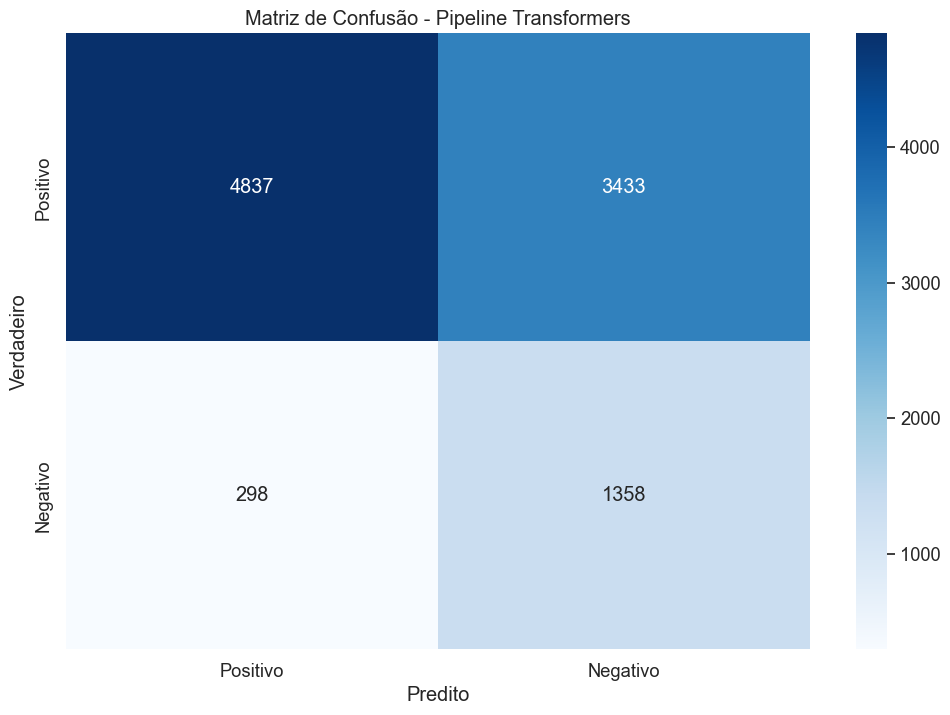


=== Performance report: Pipeline Transformers ===
Accuracy : 0.6241
Precision: 0.9420
Recall   : 0.5849
F1-score : 0.7217

--- Detailed report ---
              precision    recall  f1-score   support

         neg       0.28      0.82      0.42      1656
         pos       0.94      0.58      0.72      8270

    accuracy                           0.62      9926
   macro avg       0.61      0.70      0.57      9926
weighted avg       0.83      0.62      0.67      9926



In [11]:
# Get the predictions
preds = sentiment_pipeline(df_test["text"].tolist())

# Convert the predictions to our labels
pred_labels = ["pos" if pred["label"].upper() == "POSITIVE" else "neg" for pred in preds]

# True labels
true_labels = df_test["class"].tolist()

# Metrics
plot_confusion_matrix(true_labels, pred_labels, model_name="Pipeline Transformers")
print_classification_report(true_labels, pred_labels, model_name="Pipeline Transformers")

> 🔎 **What to notice:** the default pipeline model (DistilBERT fine-tuned on SST-2, a *movie review* dataset) reaches only **0.6241 accuracy** — worse than always answering `pos`, which would already be right for 8,270 of the 9,926 test tweets (≈ 0.83). It is far too quick to say "negative": it finds 82% of the real negative tweets, but only 28% of its "negative" answers are correct.

> ⚠️ **Limitation:** the summary lines at the top (Precision 0.9420, Recall 0.5849, F1 0.7217) are computed **only for the majority class `pos`**. They hide how the minority class `neg` does. Always read the detailed report below them: here `neg` has precision **0.28** and F1 **0.42**. The *macro avg* row (each class counts the same) is a fairer single number.

### 1.3. Try several models (simple experiments)

In [12]:
# ANSI escape codes (coloured text in the output)
def bold(text):
    return f"\033[1m{text}\033[0m"

def yellow(text):
    return f"\033[93m{text}\033[0m"

def blue(text):
    return f"\033[94m{text}\033[0m"

def green(text):
    return f"\033[92m{text}\033[0m"

def red(text):
    return f"\033[91m{text}\033[0m"

# Evaluate one pre-trained model on a dataframe
def evaluate_model(model_name, df, device, label_mappings):
    print(f"\n\033[1mEvaluating model:\033[0m \033[93m{model_name}\033[0m")

    # Create the pipeline
    sentiment_pipeline = pipeline("sentiment-analysis", model=model_name, device=device)

    # Get the predictions with a tqdm progress bar
    texts = df["text"].tolist()
    preds = []
    for text in tqdm(texts, desc=f"Processing the dataset with {model_name}"):
        preds.append(sentiment_pipeline(text)[0])  # the pipeline returns a list, so take [0]

    # Convert the predictions to our labels
    mapping = label_mappings[model_name]
    pred_labels = [mapping.get(p["label"], "Unknown") for p in preds]

    # True labels
    true_labels = df["class"].tolist()

    # Classification report
    print("\n\033[1mClassification report:\033[0m")
    print_classification_report(true_labels, pred_labels, model_name=f"{model_name} (no fine-tuning)")

    # Confusion matrix
    plot_confusion_matrix(true_labels, pred_labels, model_name=f"{model_name} (no fine-tuning)")

Each model has its own label names (`POSITIVE`, `LABEL_1`, …), so we need a **mapping** from its labels to our `pos`/`neg`:

In [13]:
model_names = [
    "distilbert-base-uncased-finetuned-sst-2-english", # https://huggingface.co/distilbert/distilbert-base-uncased-finetuned-sst-2-english
    "textattack/roberta-base-imdb", # https://textattack.readthedocs.io/en/latest/apidoc/textattack.datasets.html
    "cardiffnlp/twitter-roberta-base-sentiment", # https://huggingface.co/cardiffnlp/twitter-roberta-base-sentiment
]

label_mappings = {
    "distilbert-base-uncased-finetuned-sst-2-english": {
        "POSITIVE": "pos",
        "NEGATIVE": "neg"
    },
    "textattack/roberta-base-imdb": {
        "LABEL_0": "neg",
        "LABEL_1": "pos"
    },
    "cardiffnlp/twitter-roberta-base-sentiment": {
        "LABEL_0": "neg",
        "LABEL_1": "pos",  # neutral treated as 'pos'
        "LABEL_2": "pos"
    }
}

In [14]:
for model_name in model_names:
    print(f"\n{bold(yellow(f'Model: {model_name}'))}")

    pipe = pipeline("sentiment-analysis", model=model_name, device=device)
    text = df_test['text'][0]
    result = pipe(text)[0]
    original_label = result['label']
    score = result['score']
    final_label = label_mappings[model_name].get(original_label, "Unknown")

    label_color = green(final_label) if final_label == "Positive" else red(final_label)

    print(blue("Text:"), text)
    print(bold("Prediction:"), label_color, bold(f"(confidence: {score:.2f})"))


Model: distilbert-base-uncased-finetuned-sst-2-english


config.json:   0%|          | 0.00/629 [00:00<?, ?B/s]

...\03-applied-ai-projects\.venv\Lib\site-packages\huggingface_hub\file_download.py:144: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in ~\.cache\huggingface\hub\models--distilbert-base-uncased-finetuned-sst-2-english. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

... (18 outputs left out)

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/150 [00:00<?, ?B/s]

Device set to use cuda


Text: G Night world 
Prediction: pos (confidence: 0.57)


> 💡 The prediction is always printed in red: the colour test compares with `"Positive"`, but the mapped labels are `"pos"`/`"neg"`. Only the colour is affected.

⏳ Heavy: ~2 min on a GPU for the three models × 9,926 tweets (around half an hour on a CPU) — the saved output below comes from the original run; you do not need to re-run it.


Evaluating model: distilbert-base-uncased-finetuned-sst-2-english


Device set to use cuda

You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset

Processing the dataset with distilbert-base-uncased-finetuned-sst-2-english: 100%|██████████| 9926/9926 [00:27<00:00, 365.66it/s]



Classification report:

=== Performance report: distilbert-base-uncased-finetuned-sst-2-english (no fine-tuning) ===
Accuracy : 0.6241
Precision: 0.9420
Recall   : 0.5849
F1-score : 0.7217

--- Detailed report ---
              precision    recall  f1-score   support

         neg       0.28      0.82      0.42      1656
         pos       0.94      0.58      0.72      8270

    accuracy                           0.62      9926
   macro avg       0.61      0.70      0.57      9926
weighted avg       0.83      0.62      0.67      9926



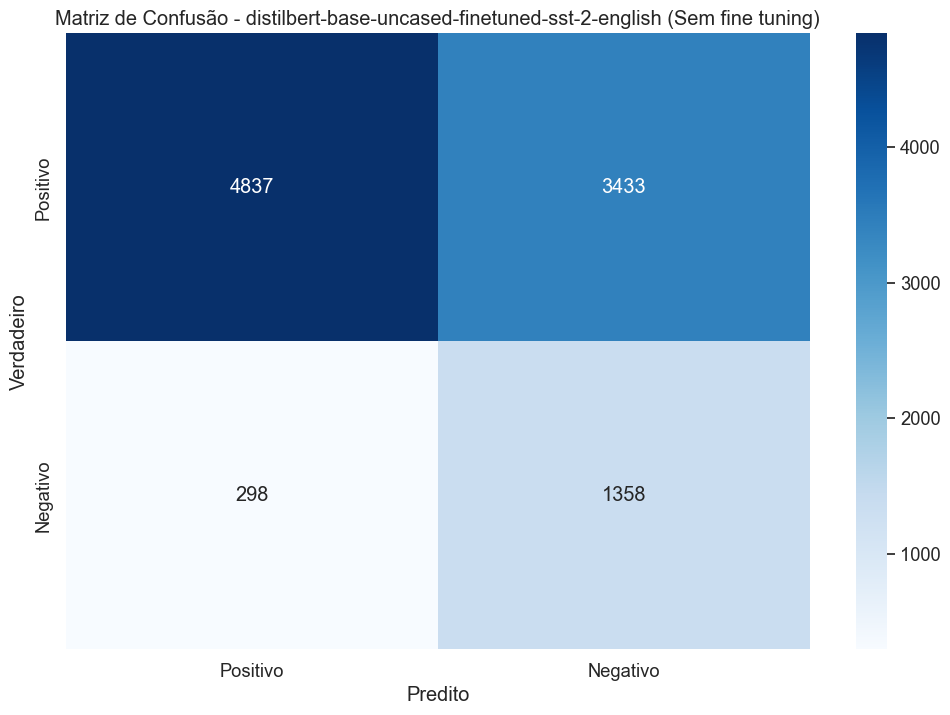


Evaluating model: textattack/roberta-base-imdb


Some weights of the model checkpoint at textattack/roberta-base-imdb were not used when initializing RobertaForSequenceClassification: ['roberta.pooler.dense.bias', 'roberta.pooler.dense.weight']
- This IS expected if you are initializing RobertaForSequenceClassification from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing RobertaForSequenceClassification from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).
Device set to use cuda
Processing the dataset with textattack/roberta-base-imdb: 100%|██████████| 9926/9926 [00:47<00:00, 208.94it/s]



Classification report:

=== Performance report: textattack/roberta-base-imdb (no fine-tuning) ===
Accuracy : 0.7246
Precision: 0.8684
Recall   : 0.7890
F1-score : 0.8268

--- Detailed report ---
              precision    recall  f1-score   support

         neg       0.28      0.40      0.33      1656
         pos       0.87      0.79      0.83      8270

    accuracy                           0.72      9926
   macro avg       0.57      0.60      0.58      9926
weighted avg       0.77      0.72      0.74      9926



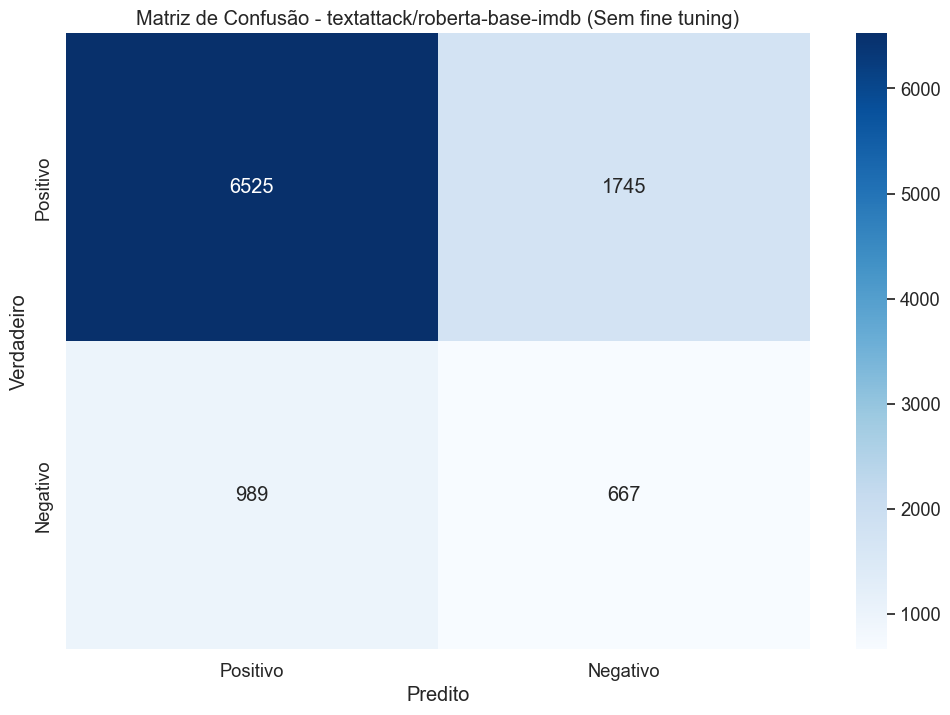


Evaluating model: cardiffnlp/twitter-roberta-base-sentiment


Device set to use cuda
Processing the dataset with cardiffnlp/twitter-roberta-base-sentiment: 100%|██████████| 9926/9926 [00:47<00:00, 209.20it/s]



Classification report:

=== Performance report: cardiffnlp/twitter-roberta-base-sentiment (no fine-tuning) ===
Accuracy : 0.8420
Precision: 0.9086
Recall   : 0.9011
F1-score : 0.9048

--- Detailed report ---
              precision    recall  f1-score   support

         neg       0.53      0.55      0.54      1656
         pos       0.91      0.90      0.90      8270

    accuracy                           0.84      9926
   macro avg       0.72      0.72      0.72      9926
weighted avg       0.84      0.84      0.84      9926



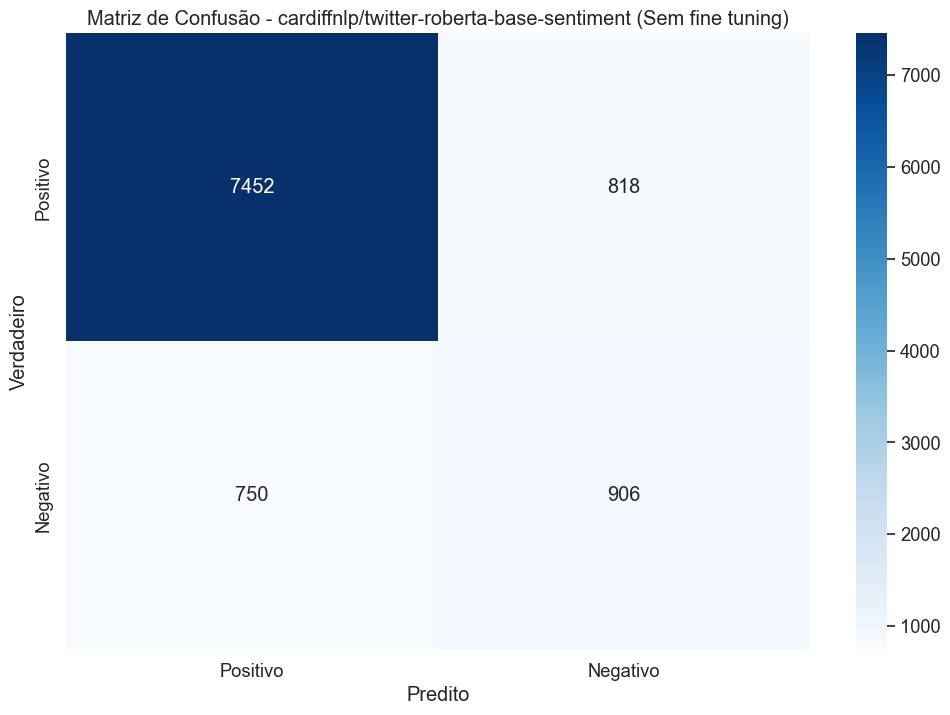

In [15]:
for model_name in model_names:
    evaluate_model(model_name, df_test, device=device, label_mappings=label_mappings)

> 🔎 **What to notice:** the training **domain** matters more than the architecture.
> - The SST-2 model (movie sentences) gets **0.6241** accuracy, the IMDb model (long movie reviews) **0.7246**.
> - `cardiffnlp/twitter-roberta-base-sentiment`, trained on **tweets**, is the best without any training on our data: **0.8420** accuracy and F1 **0.54** for `neg`.
> - It has three classes (negative / neutral / positive); mapping *neutral* to `pos` is a choice, and it helps here because most tweets in this dataset are labelled `pos`.

<a id="sec-2"></a>

## 2. 🏋️ Fine-tuning pre-trained models

**Fine-tuning** = take a model that already "knows" English and keep training it for a few epochs on *our* labelled tweets. First we split off a validation set (10% of the training set) to watch the training and stop early.

In [8]:
from datasets import Dataset

# Split a validation set off the training set
df_train_split, df_val_split = train_test_split(df_train, test_size=0.1, stratify=df_train['class'], random_state=42)

# Convert to Hugging Face Datasets
train_dataset = Dataset.from_pandas(df_train_split[['text', 'class']])
val_dataset = Dataset.from_pandas(df_val_split[['text', 'class']])
test_dataset = Dataset.from_pandas(df_test[['text', 'class']])  # only used at the very end

In [9]:
# Fit the LabelEncoder on the training set (neg -> 0, pos -> 1)
label_encoder = LabelEncoder()
label_encoder.fit(train_dataset['class'])

# Apply the transformation to the three datasets
train_dataset = train_dataset.map(lambda x: {'label': label_encoder.transform([x['class']])[0]})
val_dataset = val_dataset.map(lambda x: {'label': label_encoder.transform([x['class']])[0]})
test_dataset = test_dataset.map(lambda x: {'label': label_encoder.transform([x['class']])[0]})

Map:   0%|          | 0/35730 [00:00<?, ? examples/s]

Map:   0%|          | 0/3971 [00:00<?, ? examples/s]

Map:   0%|          | 0/9926 [00:00<?, ? examples/s]

In [10]:
from IPython.display import display, Markdown

# Pre-trained models, from the heaviest to the lightest
model_names = [
    # RoBERTa is an optimised version of BERT: heavier, but with excellent performance.
    "roberta-base",  # Robust model, very effective for many NLP tasks.

    # BERT is the classic model: heavier than DistilBERT and ALBERT, with good performance on many tasks.
    "bert-base-uncased",  # Heavier than DistilBERT, but very effective.

    # ALBERT is an optimised, more compact version of BERT, though still heavier than DistilBERT.
    "albert-base-v2",  # Lighter than BERT, still with solid performance.

    # DistilBERT is a lighter and faster version of BERT, with a good trade-off between performance and memory.
    "distilbert-base-uncased",  # Compact but efficient for common NLP tasks.

    # MiniLM is the lightest model in this list, very efficient and fast at producing text embeddings.
    "sentence-transformers/all-MiniLM-L12-v2",  # Extremely light and fast for low-latency tasks.

    "cardiffnlp/twitter-roberta-base-sentiment",  # Model tuned for sentiment analysis on tweets.
]

model_ckpt = model_names[5]

# Build and show the title as Markdown
markdown_title = f"### 2.1. Chosen model: {model_ckpt}\n"
display(Markdown(markdown_title))

### 2.1. Chosen model: cardiffnlp/twitter-roberta-base-sentiment


> 💡 The authors ran this section once per model by changing the index in `model_names[5]`. The saved outputs below are for `cardiffnlp/twitter-roberta-base-sentiment`; the results of the other runs are in [section 3](#sec-3).

In [11]:
from transformers import AutoTokenizer

# Load the tokenizer that matches the chosen model
tokenizer = AutoTokenizer.from_pretrained(model_ckpt, use_fast=True)  # use_fast=True is the default

# Tokenization function
def tokenize_function(example):
    return tokenizer(
        example["text"],
        padding=True,
        truncation=True,
        max_length=min(tokenizer.model_max_length, 512),
        return_attention_mask=True
    )

# Tokenize the whole dataset, in batches
train_dataset = train_dataset.map(tokenize_function, batched=True, remove_columns=["text"])
test_dataset = test_dataset.map(tokenize_function, batched=True, remove_columns=["text"])
val_dataset = val_dataset.map(tokenize_function, batched=True, remove_columns=["text"])

Map:   0%|          | 0/35730 [00:00<?, ? examples/s]

Map:   0%|          | 0/9926 [00:00<?, ? examples/s]

Map:   0%|          | 0/3971 [00:00<?, ? examples/s]

In [13]:
model = AutoModelForSequenceClassification.from_pretrained(model_ckpt, num_labels=2, ignore_mismatched_sizes=True)

Some weights of RobertaForSequenceClassification were not initialized from the model checkpoint at cardiffnlp/twitter-roberta-base-sentiment and are newly initialized because the shapes did not match:
- classifier.out_proj.weight: found shape torch.Size([3, 768]) in the checkpoint and torch.Size([2, 768]) in the model instantiated
- classifier.out_proj.bias: found shape torch.Size([3]) in the checkpoint and torch.Size([2]) in the model instantiated
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


> 💡 The warning is expected: the tweet model had **3** output classes and we ask for **2**, so its last layer (the *classification head*) starts from random weights. Everything before it keeps the pre-trained knowledge.

In [ ]:
# Not needed with uv / Colab (installed in the setup cell). The output below is from the original run.
# !pip install tensorboard

⏳ Heavy: ~12.5 min on a GPU (RTX 4060) for this model, 9–32 min for the others in the table; many hours on a CPU — the saved output below comes from the original run; you do not need to re-run it.

In [14]:
from transformers import Trainer, TrainingArguments, EarlyStoppingCallback
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Metrics computed on the validation set after every epoch
def compute_metrics(p):
    preds = np.argmax(p.predictions, axis=1)
    labels = p.label_ids
    return {
        "accuracy": accuracy_score(labels, preds),
        "precision": precision_score(labels, preds, average="weighted"),
        "recall": recall_score(labels, preds, average="weighted"),
        "f1": f1_score(labels, preds, average="weighted"),
    }

# Tuned training arguments
training_args = TrainingArguments(
    output_dir=str(models_dir() / "tweets_transformer_checkpoints"),  # checkpoints + TensorBoard logs
    eval_strategy="epoch",
    save_strategy="epoch",
    logging_strategy="steps",
    logging_steps=100,
    save_steps=500,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    num_train_epochs=10,
    learning_rate=1e-5,
    weight_decay=0.0,
    adam_epsilon=1e-6,
    gradient_accumulation_steps=4,
    fp16=True,
    dataloader_num_workers=4,
    dataloader_pin_memory=True,
    warmup_steps=0,
    seed=42,
    load_best_model_at_end=True,
    metric_for_best_model="f1",
    greater_is_better=True,
    report_to="tensorboard",
)

# Trainer with early stopping
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    tokenizer=tokenizer,
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=2)],
)

# Start training
trainer.train()

<ipython-input>:42: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  trainer = Trainer(


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.259800,0.237998,0.910854,0.907362,0.910854,0.903597
2,0.214200,0.219828,0.914127,0.911843,0.914127,0.912727
3,0.168300,0.245095,0.911106,0.910164,0.911106,0.910603
4,0.135500,0.264596,0.911609,0.910673,0.911609,0.911109


TrainOutput(global_step=2236, training_loss=0.20245379348133885, metrics={'train_runtime': 757.7876, 'train_samples_per_second': 471.504, 'train_steps_per_second': 7.364, 'total_flos': 6989544157860840.0, 'train_loss': 0.20245379348133885, 'epoch': 4.0})

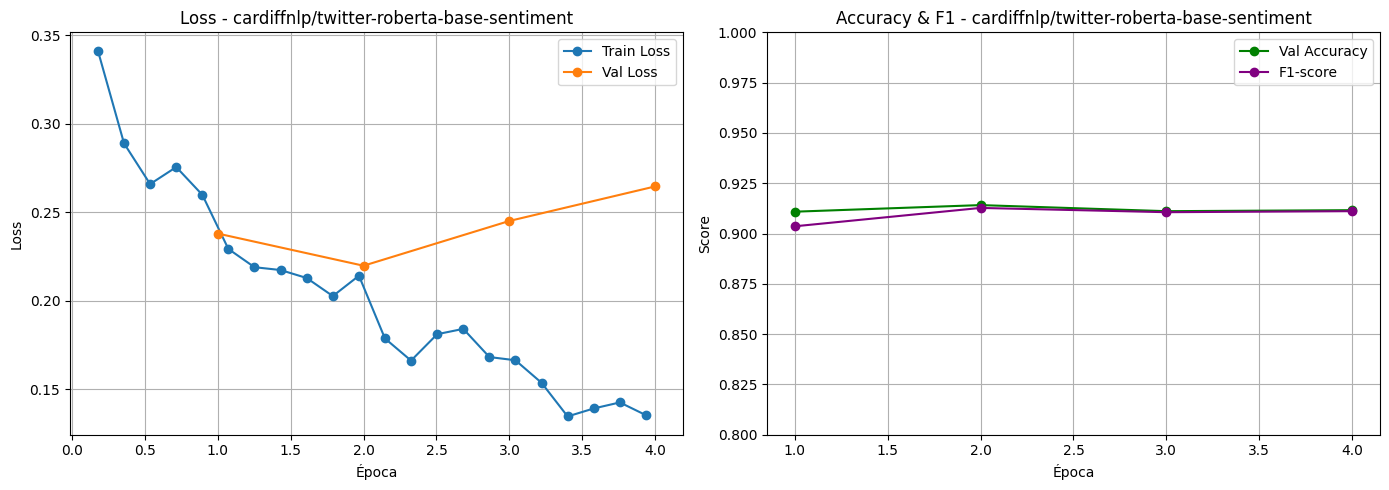

In [15]:
plot_training_history_from_trainer(trainer, model_name=model_ckpt)

> 🔎 **What to notice:** training stopped at **epoch 4 of 10**. The validation F1 peaked at epoch 2 (0.9127) and did not improve for 2 more epochs, so **early stopping** ended the run and `load_best_model_at_end` restored the epoch-2 weights. Meanwhile the training loss keeps falling (0.2598 → 0.1355) while the validation loss rises after epoch 2 (0.2198 → 0.2646): the model starts to memorise the training tweets — the first sign of **overfitting**.
>
> The validation metrics in this table are **weighted averages** over both classes (`average="weighted"` in `compute_metrics`), so they are not directly comparable with the `pos`-only numbers of the reports.

⏳ Heavy: ~1 min on a GPU to predict the 9,926 test tweets — the saved output below comes from the original run; you do not need to re-run it.


=== Performance report: cardiffnlp/twitter-roberta-base-sentiment ===
Accuracy : 0.9075
Precision: 0.9377
Recall   : 0.9522
F1-score : 0.9449

--- Detailed report ---
              precision    recall  f1-score   support

         neg       0.74      0.68      0.71      1656
         pos       0.94      0.95      0.94      8270

    accuracy                           0.91      9926
   macro avg       0.84      0.82      0.83      9926
weighted avg       0.90      0.91      0.91      9926



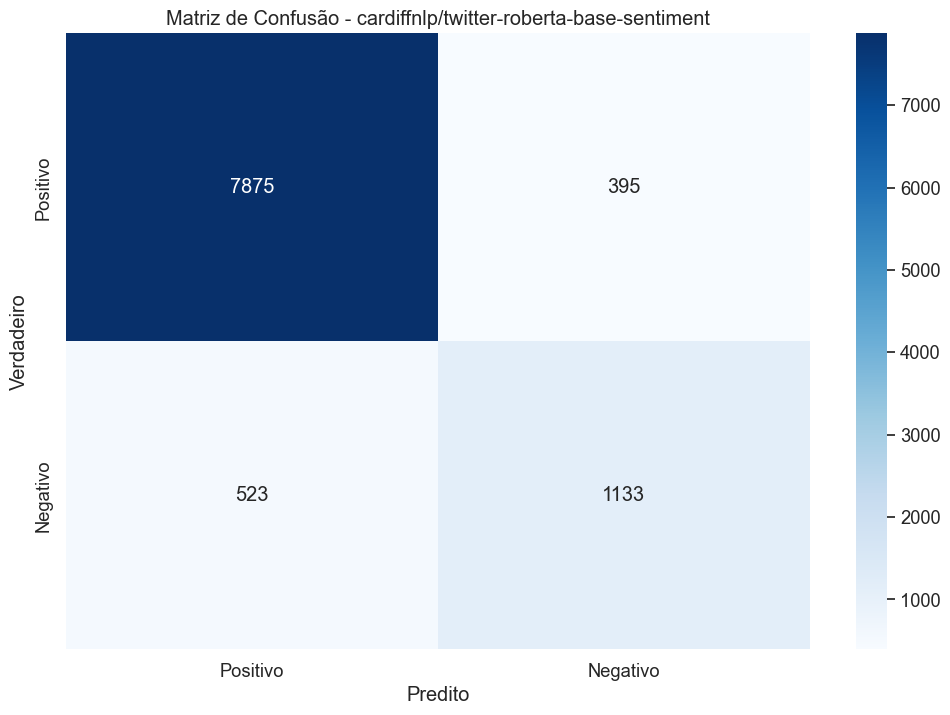

In [16]:
# Predict the test set
preds = trainer.predict(test_dataset)
y_pred = np.argmax(preds.predictions, axis=1)  # model predictions
y_true = preds.label_ids  # true labels

# Show the classification report
print_classification_report(y_true, y_pred, model_name=model_ckpt, pos_label=1)

# Show the confusion matrix
plot_confusion_matrix(y_true, y_pred, model_name=model_ckpt, labels=[1,0])

> 🔎 **What to notice:** the same tweet model, after fine-tuning, goes from **0.8420 → 0.9075** accuracy, and the `neg` class improves the most: F1 **0.54 → 0.71**. That is the payoff of a few minutes of training on our own data.

> ⚠️ **Limitation:** some tweets appear in **both** the training and the test set (219 test tweets are identical to a training tweet, 283 if you ignore upper/lower case and extra spaces). For those tweets the model has already seen the answer during training, so the test score is slightly optimistic. A clean evaluation removes the duplicates from the training set before training.

In [111]:
# Optional: frees disk space used by the Hugging Face cache. The sub-command is "delete-cache",
# which is why the original run below shows an error.
# !huggingface-cli cache delete

usage: huggingface-cli <command> [<args>]
huggingface-cli: error: argument {download,upload,repo-files,env,login,whoami,logout,auth,repo,lfs-enable-largefiles,lfs-multipart-upload,scan-cache,delete-cache,tag,version,upload-large-folder}: invalid choice: 'cache' (choose from 'download', 'upload', 'repo-files', 'env', 'login', 'whoami', 'logout', 'auth', 'repo', 'lfs-enable-largefiles', 'lfs-multipart-upload', 'scan-cache', 'delete-cache', 'tag', 'version', 'upload-large-folder')


<a id="sec-3"></a>

## 3. 📊 Results

### 📊 Comparison table of the fine-tuned NLP models

Test set (9,926 tweets). As in the reports above, precision, recall and F1 are for the class `pos`.

| 🧠 Model                              | 🎯 Accuracy | 🎯 Precision | 📈 Recall | 📊 F1-score | 🔁 Epochs | ⏱️ Run time |
|---------------------------------------|-------------|--------------|-----------|-------------|-----------|--------------------|
| 🟤 cardiffnlp/twitter-roberta-base-sentiment | **0.9075**   | **0.9377**    | **0.9522** | **0.9449**   | 4/10     | 12:26              |
| 🔵 roberta-base                       | 0.9070       | 0.9396        | 0.9495     | 0.9445       | 9/10     | 30:57              |
| 🟢 bert-base-uncased                  | 0.8901       | 0.9107        | 0.9625     | 0.9359       | 5/10     | 14:37              |
| 🟣 albert-base-v2                     | 0.8883       | 0.9063        | 0.9658     | 0.9351       | 7/10     | 31:54              |
| 🟡 distilbert-base-uncased            | 0.8797       | 0.9235        | 0.9329     | 0.9282       | 6/10     | 11:00              |
| 🟠 all-MiniLM-L12-v2                  | 0.8867       | 0.9300        | 0.9343     | 0.9321       | 6/10     | 08:59              |

> 🔎 **What to notice:** the model that was **already trained on tweets** wins, and it needed the fewest epochs (4) — starting close to the task saves time. `roberta-base` gets almost the same score but needs 9 epochs and 2.5× the time. The small `all-MiniLM-L12-v2` is the fastest (≈ 9 min) and loses less than 2 points of accuracy.

### 🖼️ Saved plots from the other fine-tuning runs

The outputs above are for `cardiffnlp/twitter-roberta-base-sentiment`. These images were saved by the authors from the runs of the other models (same code, different `model_ckpt`). `deberta-v3-base` was also tried; only its plots were saved, so it has no row in the table.

<details><summary><b>roberta-base</b> — training history and confusion matrix</summary>

![roberta-base training history](images/roberta-base-history.png)

![roberta-base confusion matrix](images/roberta-base-confusionMatrix.png)

</details>

<details><summary><b>bert-base-uncased</b> — training history and confusion matrix</summary>

![bert-base-uncased training history](images/bert-base-uncased-history.png)

![bert-base-uncased confusion matrix](images/bert-base-uncased-confusionMatrix.png)

</details>

<details><summary><b>albert-base-v2</b> — training history and confusion matrix</summary>

![albert-base-v2 training history](images/albert-base-v2-history.png)

![albert-base-v2 confusion matrix](images/albert-base-v2-confusionMatrix.png)

</details>

<details><summary><b>distilbert-base-uncased</b> — training history and confusion matrix</summary>

![distilbert-base-uncased training history](images/distilbert-base-uncased-history.png)

![distilbert-base-uncased confusion matrix](images/distilbert-base-uncased-confusionMatrix.png)

</details>

<details><summary><b>all-MiniLM-L12-v2</b> — training history and confusion matrix</summary>

![all-MiniLM-L12-v2 training history](images/all-MiniLM-L12-v2-history.png)

![all-MiniLM-L12-v2 confusion matrix](images/all-MiniLM-L12-v2-confusionMatrix.png)

</details>

<details><summary><b>deberta-v3-base</b> — training history and confusion matrix</summary>

![deberta-v3-base training history](images/deberta-v3-base-history.png)

![deberta-v3-base confusion matrix](images/deberta-v3-base-confusionMatrix.png)

</details>

> 💡 **Note:**
> To see the training logs in **TensorBoard**:
>
> 1. Open a terminal in the folder that holds the log files (`events.out.tfevents…`). In the original project they were in `notebooks\logs`; with this notebook the `Trainer` writes them inside the `output_dir` set above (in the `models/` folder).
> 2. Run:
>
> ```bash
> tensorboard --logdir=./logs
> ```
>
> (replace `./logs` with the folder from step 1). Then open the TensorBoard dashboard in your browser, usually at `http://localhost:6006`.

In [112]:
del trainer

- - -

<a id="sec-4"></a>

## 4. 🔧 Optuna (hyperparameter search)

**Optuna** tries different combinations of hyperparameters (learning rate, batch size, …) and keeps the one with the best validation score. The cell below is stored as a **raw cell** (it is shown but not executed, and has no saved output); to try it, change the cell type to *Code* and install `optuna`.

⏳ Heavy: 10 trials × a full fine-tuning each — many hours on a GPU. The cell was kept as text in the original project; you do not need to run it.

> ⚠️ **Limitation:** every trial trains the **same `model` object**. From the second trial on, the model starts from the weights that the previous trial already fine-tuned, so the trials are not independent and their scores cannot be compared fairly. A correct search creates a fresh model inside each trial (for example with `Trainer(model_init=...)` and `trainer.hyperparameter_search(...)`). Note also that the search maximises validation **accuracy**, while the final training above picks the best epoch by **F1**.

### 🔧 Best parameters found

After tuning with **Optuna** and adjusting the training strategy, the authors report these hyperparameters as the ones that gave the best performance on the classification task (they are the ones used in section 2):

| Parameter                      | Value        |
|---------------------------------|--------------|
| `learning_rate`                | `1e-5`       |
| `batch_size`                   | `16`         |
| `eval_batch_size`              | `32`         |
| `num_train_epochs`             | `10`         |
| `warmup_steps`                 | `0`          |
| `weight_decay`                 | `0.0`        |
| `adam_epsilon`                 | `1e-6`       |
| `gradient_accumulation_steps`  | `4`          |
| `fp16`                         | `True`       |
| `early_stopping_patience`      | `2`          |
| `dataloader_num_workers`       | `4`          |
| `dataloader_pin_memory`        | `True`       |
| `seed`                         | `42`         |
| `metric_for_best_model`        | `f1`         |
| `greater_is_better`            | `True`       |
| `save_strategy`                | `"epoch"`    |
| `eval_strategy`                | `"epoch"`    |
| `load_best_model_at_end`       | `True`       |

> ⚙️ These parameters were chosen to maximise the **F1-score**, while keeping the training stable, efficient and monitored in **TensorBoard**.

<a id="sec-5"></a>

## 5. 🏆 Comparing the results

Ready-made pipelines (**no fine-tuning**, top block, section 1) against models **fine-tuned on our tweets** (bottom block, sections 2–3). The pipeline numbers and the fine-tuned `cardiffnlp` numbers come from the classification reports above. For the other five fine-tuned models only the accuracy was saved (the table of section 3), so their macro-F1 and `neg` F1 are left empty rather than guessed.

How to read it: **accuracy** (grey), **macro-F1** (blue) and the **F1 of the `neg` class** (red); the dashed lines are the "always say `pos`" baseline for accuracy (grey) and macro-F1 (blue). Inside each block the best model is at the top.

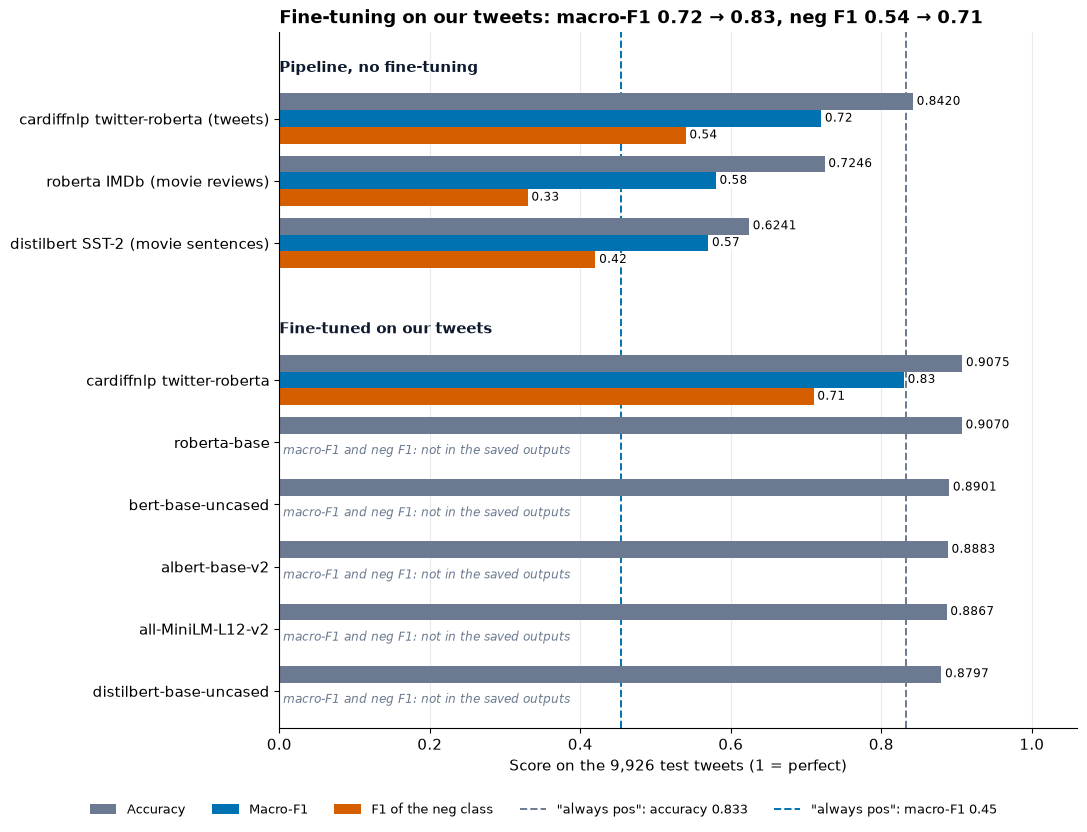

In [ ]:
# 🏆 Transformers on the test set: numbers copied from the reports of sections 1-2 and the table of section 3
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from src.plotting import apply_style, PALETTE

apply_style()

# None = not in the saved outputs (only the accuracy of these runs was kept, in the table of section 3)
results = pd.DataFrame([
    # (model, group, accuracy, macro-F1, F1 of neg)
    ('distilbert SST-2 (movie sentences)',  'Pipeline, no fine-tuning', 0.6241, 0.57, 0.42),
    ('roberta IMDb (movie reviews)',        'Pipeline, no fine-tuning', 0.7246, 0.58, 0.33),
    ('cardiffnlp twitter-roberta (tweets)', 'Pipeline, no fine-tuning', 0.8420, 0.72, 0.54),
    ('cardiffnlp twitter-roberta',          'Fine-tuned on our tweets', 0.9075, 0.83, 0.71),
    ('roberta-base',                        'Fine-tuned on our tweets', 0.9070, None, None),
    ('bert-base-uncased',                   'Fine-tuned on our tweets', 0.8901, None, None),
    ('albert-base-v2',                      'Fine-tuned on our tweets', 0.8883, None, None),
    ('distilbert-base-uncased',             'Fine-tuned on our tweets', 0.8797, None, None),
    ('all-MiniLM-L12-v2',                   'Fine-tuned on our tweets', 0.8867, None, None),
], columns=["model", "group", "accuracy", "macro_f1", "f1_neg"])

# "Always say pos" baseline, from the support column of the reports (9,926 test tweets)
n_pos, n_neg = 8270, 1656
base_acc = n_pos / (n_pos + n_neg)        # it is right for every pos and wrong for every neg
base_macro = (2 * base_acc / (1 + base_acc) + 0) / 2  # F1 of pos = 2PR/(P+R) with P=base_acc, R=1; F1 of neg = 0

# One block per group; inside a block the best model is at the top (macro-F1, ties broken by accuracy)
group_order = {g: i for i, g in enumerate(results["group"].unique())}
results["g"] = results["group"].map(group_order)
results = results.sort_values(["g", "macro_f1", "accuracy"], ascending=[True, False, False],
                              na_position="last").reset_index(drop=True)
y = results.index.to_numpy() + 1.2 * results["g"].to_numpy()  # extra space between the groups

bars = [("accuracy", "Accuracy", PALETTE["grey"], 4),
        ("macro_f1", "Macro-F1", PALETTE["blue"], 2),
        ("f1_neg", "F1 of the neg class", PALETTE["red"], 2)]
h = 0.27  # height of one bar
fig, ax = plt.subplots(figsize=(11, 0.62 * len(results) + 1.4 + 0.5 * results['g'].nunique()))
for k, (col, name, color, decimals) in enumerate(bars):
    pos = y + (k - 1) * h
    ax.barh(pos, results[col].fillna(0), height=h, color=color, label=name, zorder=2)
    for yi, v in zip(pos, results[col]):
        if pd.notna(v):
            ax.text(v + 0.005, yi, f"{v:.{decimals}f}", va="center", fontsize=8.5,
                    bbox=dict(facecolor="white", edgecolor="none", pad=0.3), zorder=3)
        elif col == "macro_f1":  # a missing value is shown as a note, never as a number
            ax.text(0.005, yi + h / 2, "macro-F1 and neg F1: not in the saved outputs", va="center",
                    fontsize=8.5, color=PALETTE["grey"], style="italic")

for g, first in results.groupby("group", sort=False)["g"].idxmin().items():
    ax.text(0, y[first] - 0.75, g, fontsize=11, fontweight="bold", color=PALETTE["navy"])

# The "always say pos" baseline (dashed lines, same colour as the metric they belong to)
ax.axvline(base_acc, color=PALETTE["grey"], ls="--", lw=1.4, zorder=1, label=f'"always pos": accuracy {base_acc:.3f}')
ax.axvline(base_macro, color=PALETTE["blue"], ls="--", lw=1.4, zorder=1, label=f'"always pos": macro-F1 {base_macro:.2f}')

ax.set_yticks(y, results["model"])
ax.set_ylim(y.max() + 0.6, y.min() - 1.4)  # reversed limits: first row at the top
ax.set_xlim(0, 1.06)
ax.set_xlabel('Score on the 9,926 test tweets (1 = perfect)')
ax.grid(axis="y", visible=False)
ax.set_title('Fine-tuning on our tweets: macro-F1 0.72 → 0.83, neg F1 0.54 → 0.71')
fig.tight_layout()
handles, labels = ax.get_legend_handles_labels()  # the two dashed lines come first: move them to the end
fig.legend(handles[2:] + handles[:2], labels[2:] + labels[:2], loc="upper center", bbox_to_anchor=(0.5, 0.0),
           ncol=5, fontsize=9.5)
plt.show()

> 👀 **What to notice:**
> - **Without fine-tuning, the training domain decides:** the two movie-review models are *below* the "always `pos`" accuracy (0.6241 and 0.7246), the tweet model is close to it (0.8420) and has by far the best macro-F1 of the three (0.72).
> - **Low accuracy is not always "worse":** the SST-2 model has the lowest accuracy, yet its macro-F1 (0.57) is well above the 0.45 of "always `pos`", because it finds 82% of the negative tweets.
> - **Fine-tuning is the big jump:** the same tweet model goes to accuracy 0.9075, macro-F1 0.83 and `neg` F1 0.71. All six fine-tuned models clear the accuracy baseline (0.8797–0.9075).

<a id="sec-6"></a>

## 6. 🏁 The whole project

The best model of each family from notebooks 02.1–02.4, side by side (one row per family, the notebook in brackets). "Best" = highest macro-F1, ties broken by accuracy. All numbers are copied from the saved classification reports of each notebook.

How to read it: the same bars and dashed lines as above, ordered by macro-F1. 02.3 used the full test file (9,985 tweets, "always `pos`" accuracy 0.8324) while the other notebooks dropped the empty rows (9,926 tweets, 0.8332), so the dashed lines are the 9,926-tweet ones; the difference is less than 0.001. The generative LLMs of 02.5 are not here: they were measured on a different dataset.

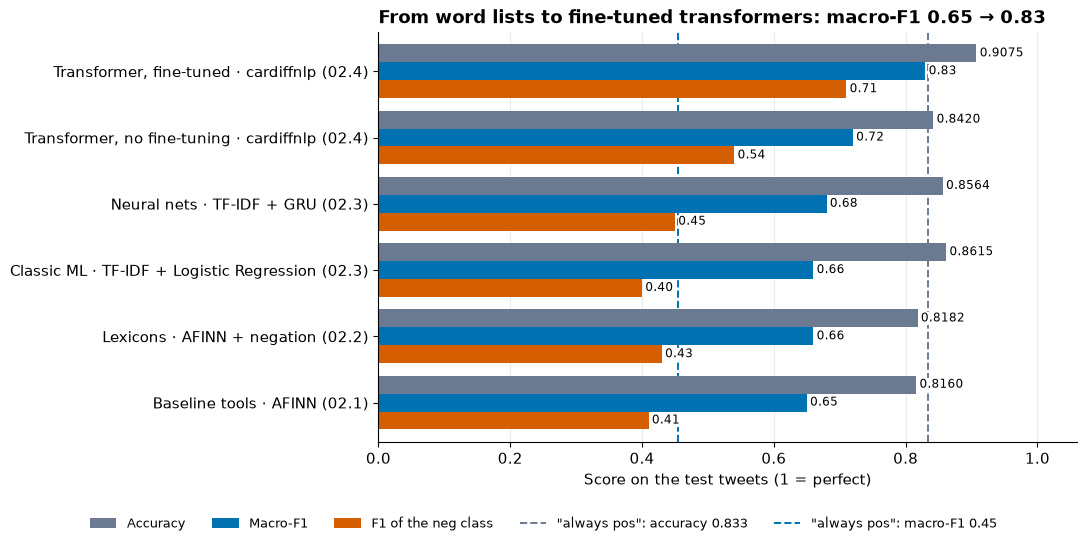

In [ ]:
# 🏁 Best model of each family, 02.1-02.4: numbers copied from the saved reports
# 02.1 AFINN (section 3.4) · 02.2 AFINN with negation (section 3.3) · 02.3 Logistic Regression
# and GRU on TF-IDF (sections 2 and 7) · 02.4 cardiffnlp without / with fine-tuning (sections 1 and 2)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from src.plotting import apply_style, PALETTE

apply_style()

results = pd.DataFrame([
    # (model, accuracy, macro-F1, F1 of neg)
    ('Baseline tools · AFINN (02.1)',                    0.8160, 0.65, 0.41),
    ('Lexicons · AFINN + negation (02.2)',               0.8182, 0.66, 0.43),
    ('Classic ML · TF-IDF + Logistic Regression (02.3)', 0.8615, 0.66, 0.40),
    ('Neural nets · TF-IDF + GRU (02.3)',                0.8564, 0.68, 0.45),
    ('Transformer, no fine-tuning · cardiffnlp (02.4)',  0.8420, 0.72, 0.54),
    ('Transformer, fine-tuned · cardiffnlp (02.4)',      0.9075, 0.83, 0.71),
], columns=["model", "accuracy", "macro_f1", "f1_neg"])

# "Always say pos" baseline, from the support column of the reports (9,926 test tweets)
n_pos, n_neg = 8270, 1656
base_acc = n_pos / (n_pos + n_neg)        # it is right for every pos and wrong for every neg
base_macro = (2 * base_acc / (1 + base_acc) + 0) / 2  # F1 of pos = 2PR/(P+R) with P=base_acc, R=1; F1 of neg = 0

# Best model at the top: sort by macro-F1 (ties broken by accuracy)
results = results.sort_values(["macro_f1", "accuracy"], ascending=False).reset_index(drop=True)
y = np.arange(len(results))

bars = [("accuracy", "Accuracy", PALETTE["grey"], 4),
        ("macro_f1", "Macro-F1", PALETTE["blue"], 2),
        ("f1_neg", "F1 of the neg class", PALETTE["red"], 2)]
h = 0.27  # height of one bar
fig, ax = plt.subplots(figsize=(11, 0.62 * len(results) + 1.4))
for k, (col, name, color, decimals) in enumerate(bars):
    pos = y + (k - 1) * h
    ax.barh(pos, results[col].fillna(0), height=h, color=color, label=name, zorder=2)
    for yi, v in zip(pos, results[col]):
        if pd.notna(v):
            ax.text(v + 0.005, yi, f"{v:.{decimals}f}", va="center", fontsize=8.5,
                    bbox=dict(facecolor="white", edgecolor="none", pad=0.3), zorder=3)
        elif col == "macro_f1":  # a missing value is shown as a note, never as a number
            ax.text(0.005, yi + h / 2, "macro-F1 and neg F1: not in the saved outputs", va="center",
                    fontsize=8.5, color=PALETTE["grey"], style="italic")

# The "always say pos" baseline (dashed lines, same colour as the metric they belong to)
ax.axvline(base_acc, color=PALETTE["grey"], ls="--", lw=1.4, zorder=1, label=f'"always pos": accuracy {base_acc:.3f}')
ax.axvline(base_macro, color=PALETTE["blue"], ls="--", lw=1.4, zorder=1, label=f'"always pos": macro-F1 {base_macro:.2f}')

ax.set_yticks(y, results["model"])
ax.set_ylim(y.max() + 0.6, y.min() - 0.6)  # reversed limits: first row at the top
ax.set_xlim(0, 1.06)
ax.set_xlabel('Score on the test tweets (1 = perfect)')
ax.grid(axis="y", visible=False)
ax.set_title('From word lists to fine-tuned transformers: macro-F1 0.65 → 0.83')
fig.tight_layout()
handles, labels = ax.get_legend_handles_labels()  # the two dashed lines come first: move them to the end
fig.legend(handles[2:] + handles[:2], labels[2:] + labels[:2], loc="upper center", bbox_to_anchor=(0.5, 0.0),
           ncol=5, fontsize=9.5)
plt.show()

> 👀 **What to notice:**
> - **The ready-made tools and the lexicons stay below the "always `pos`" accuracy line**; the trained models of 02.3 and the tweet transformers cross it.
> - **Macro-F1 creeps up slowly through the classic methods** (0.65 → 0.66 → 0.66 → 0.68): better features and bigger models barely change how well the negative tweets are found.
> - **A transformer trained on tweets, with no training on our data, already beats all of them** (macro-F1 0.72, `neg` F1 0.54) — and **fine-tuning** it gives the biggest jump of the project: macro-F1 **0.83**, `neg` F1 **0.71**, accuracy **0.9075**.
> - The same conclusion as the project report: on short, informal text like tweets, models that read words *in context* win.

<a id="summary"></a>

## 📌 Summary

- A ready-made **pipeline** classifies tweets with zero training, but only works well if it was trained on similar text: movie-review models got 0.62–0.72 accuracy, the **tweet** model 0.8420.
- Every pre-trained model has its own labels; a **label mapping** turns them into our `pos`/`neg` (and *neutral* has to go somewhere).
- **Fine-tuning** the tweet model on our 35,730 training tweets lifted accuracy to **0.9075** and the `neg` F1 from 0.54 to 0.71 — the best result in this notebook.
- **Early stopping** on a validation set stops training when the validation score stops improving, before the model overfits.
- Bigger is not always better: the domain-matched model beat `roberta-base`, `bert-base-uncased` and `albert-base-v2`, and trained faster.
- Watch the evaluation: report the minority class `neg`, not only `pos`, and remove train/test duplicates.

**Next:** in 02.5 we skip training altogether and ask **generative LLMs** (Gemini, Llama-2) to label sentiment with just a prompt.

---
<div align="center">

⬅️ [Previous: 02.3 · Tweets: machine learning](02.3_Tweets_Machine_Learning.ipynb) &nbsp;·&nbsp; 🏠 [Lesson 03](../../README.md) &nbsp;·&nbsp; [Next: 02.5 · Generative LLMs](02.5_Tweets_Generative_LLMs.ipynb) ➡️

**The AI Learning Hub** · Lesson 03 — Applied AI: unstructured data<br>
MIT License

</div>